# 02 · Appointment No-show Prediction
### Logistic Regression + Decision Tree

**Dataset:** `data/appointments.csv` — 110,527 medical appointments (Brazil, 2016).

**Goal:** predict whether an appointment will be missed, so the hospital can target reminders and overbooking decisions.

**Two models:**
1. **Logistic Regression** — probability of no-show, with calibrated probabilities.
2. **Decision Tree** — interpretable appointment classification and rule discovery.

Both models use the same preprocessing pipeline and an 80/20 stratified train/test split. A validation split is used to choose the classification threshold before the final model is fitted on the full training set.
        

In [1]:
from pathlib import Path
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

%matplotlib inline
warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.25})

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "appointments.csv"
MODEL_DIR = ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)
print("Project root:", ROOT)
print("Using:", DATA_PATH)
        

Project root: C:\Users\Lenovo\health_analytics
Using: C:\Users\Lenovo\health_analytics\data\appointments.csv


## 1. Load and inspect appointments

In [2]:
raw = pd.read_csv(DATA_PATH)
print(f"Rows: {raw.shape[0]:,} | Columns: {raw.shape[1]}")
print("Missing values:", int(raw.isna().sum().sum()))
print("Duplicate appointment IDs:", int(raw["AppointmentID"].duplicated().sum()))
print("Unique patients:", raw["PatientId"].nunique())
raw.head()
        

Rows: 110,527 | Columns: 14
Missing values: 0
Duplicate appointment IDs: 0
Unique patients: 62299


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


## 2. Clean and engineer appointment features

In [3]:
df = raw[raw["Age"] >= 0].copy()
for column in ["ScheduledDay", "AppointmentDay"]:
    df[column] = pd.to_datetime(df[column]).dt.tz_localize(None)

df["lead_time_days"] = (
    df["AppointmentDay"].dt.normalize() - df["ScheduledDay"].dt.normalize()
).dt.days.clip(lower=0)
df["weekday"] = df["AppointmentDay"].dt.day_name()
df["age_group"] = pd.cut(
    df["Age"],
    bins=[-1, 17, 34, 49, 64, 120],
    labels=["0-17", "18-34", "35-49", "50-64", "65+"],
).astype(str)
df["has_handicap"] = (df["Handcap"] > 0).astype(int)
df["chronic_conditions"] = (
    df["Hipertension"] + df["Diabetes"] + df["Alcoholism"] + df["has_handicap"]
)
df["is_same_day"] = (df["lead_time_days"] == 0).astype(int)
df["target"] = (df["No-show"] == "Yes").astype(int)

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
age_order = ["0-17", "18-34", "35-49", "50-64", "65+"]
lead_order = ["Same day", "1-3 days", "4-7 days", "8-14 days", "15-30 days", "31+ days"]
df["lead_bin"] = pd.cut(
    df["lead_time_days"],
    bins=[-1, 0, 3, 7, 14, 30, 365],
    labels=lead_order,
)

print(f"Modelling rows: {len(df):,}")
print(f"No-show rate: {df['target'].mean():.1%}")
df[["Age", "lead_time_days", "weekday", "age_group", "chronic_conditions", "target"]].head()
        

Modelling rows: 110,526
No-show rate: 20.2%


,Age,lead_time_days,weekday,age_group,chronic_conditions,target
0,62,0,Friday,50-64,1,0
1,56,0,Friday,50-64,0,0
2,62,0,Friday,50-64,0,0
3,8,0,Friday,0-17,0,0
4,56,0,Friday,50-64,2,0


## 3. Exploratory view of no-show behaviour

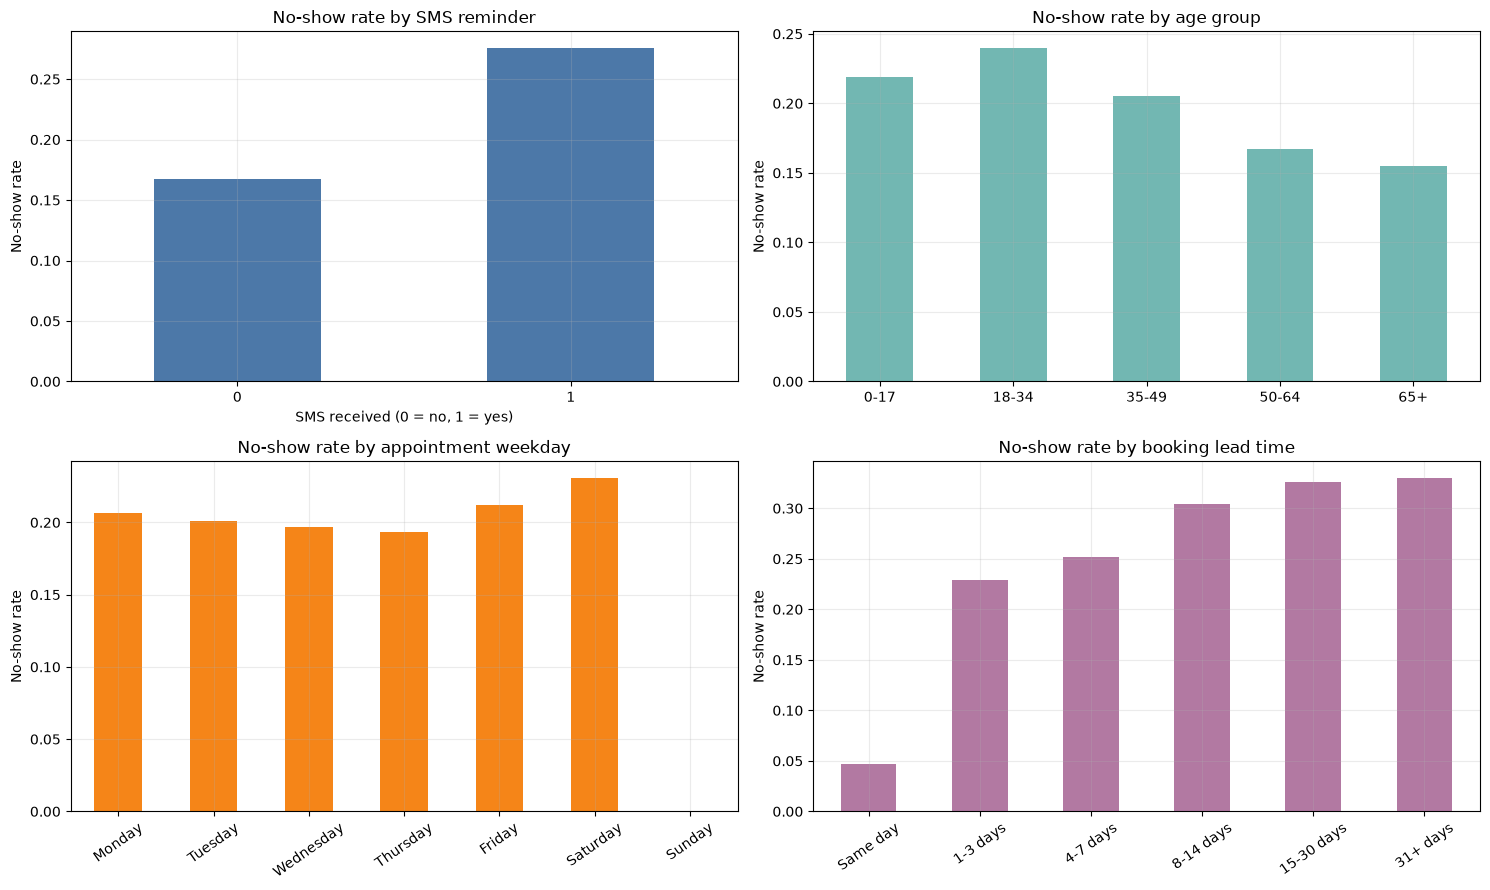

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

df.groupby("SMS_received")["target"].mean().plot(kind="bar", ax=axes[0, 0], color="#4c78a8")
axes[0, 0].set_title("No-show rate by SMS reminder")
axes[0, 0].set_xlabel("SMS received (0 = no, 1 = yes)")
axes[0, 0].set_ylabel("No-show rate")
axes[0, 0].tick_params(axis="x", rotation=0)

df.groupby("age_group", observed=True)["target"].mean().reindex(age_order).plot(
    kind="bar", ax=axes[0, 1], color="#72b7b2"
)
axes[0, 1].set_title("No-show rate by age group")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("No-show rate")
axes[0, 1].tick_params(axis="x", rotation=0)

df.groupby("weekday")["target"].mean().reindex(weekday_order).plot(
    kind="bar", ax=axes[1, 0], color="#f58518"
)
axes[1, 0].set_title("No-show rate by appointment weekday")
axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("No-show rate")
axes[1, 0].tick_params(axis="x", rotation=35)

df.groupby("lead_bin", observed=True)["target"].mean().reindex(lead_order).plot(
    kind="bar", ax=axes[1, 1], color="#b279a2"
)
axes[1, 1].set_title("No-show rate by booking lead time")
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("No-show rate")
axes[1, 1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()
        

In [5]:
neighbourhood_stats = (
    df.groupby("Neighbourhood")["target"]
    .agg(no_show_rate="mean", appointments="count")
    .query("appointments >= 100")
    .sort_values("no_show_rate", ascending=False)
)
neighbourhood_stats.head(15).round(3)
        

,no_show_rate,appointments
Neighbourhood,,
SANTOS DUMONT,0.289,1276
SANTA CECÍLIA,0.275,448
SANTA CLARA,0.265,506
ITARARÉ,0.263,3514
JESUS DE NAZARETH,0.244,2853
HORTO,0.240,175
ILHA DO PRÍNCIPE,0.235,2266
CARATOÍRA,0.230,2565
ANDORINHAS,0.230,2262


## 4. Define features and split the data

In [6]:
numeric_features = [
    "Age",
    "lead_time_days",
    "Scholarship",
    "Hipertension",
    "Diabetes",
    "Alcoholism",
    "SMS_received",
    "has_handicap",
    "chronic_conditions",
    "is_same_day",
]
categorical_features = ["Gender", "weekday", "Neighbourhood", "age_group"]
feature_columns = numeric_features + categorical_features

X = df[feature_columns]
y = df["target"]

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    random_state=42,
    stratify=y_train_full,
)

print(f"Train: {len(X_train):,} | Validation: {len(X_val):,} | Test: {len(X_test):,}")
print(f"Train no-show rate: {y_train.mean():.1%} | Test no-show rate: {y_test.mean():.1%}")
        

Train: 70,736 | Validation: 17,684 | Test: 22,106
Train no-show rate: 20.2% | Test no-show rate: 20.2%


## 5. Shared preprocessing and threshold selection

In [7]:
def build_preprocessor():
    return ColumnTransformer(
        [
            ("numeric", StandardScaler(), numeric_features),
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore", drop="first"),
                categorical_features,
            ),
        ]
    )


def calibrated_fit(estimator, X_fit, y_fit):
    return CalibratedClassifierCV(
        estimator=estimator,
        method="sigmoid",
        cv=3,
        ensemble=False,
    ).fit(X_fit, y_fit)


def best_f1_threshold(y_true, probabilities):
    precision, recall, thresholds = precision_recall_curve(y_true, probabilities)
    f1_scores = 2 * precision * recall / (precision + recall + 1e-9)
    best_index = int(np.argmax(f1_scores[:-1]))
    return float(thresholds[best_index]), float(f1_scores[best_index])


def evaluate_predictions(name, y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions).ravel()
    return {
        "model": name,
        "threshold": round(float(threshold), 4),
        "roc_auc": round(float(roc_auc_score(y_true, probabilities)), 4),
        "accuracy": round(float(accuracy_score(y_true, predictions)), 4),
        "precision": round(float(precision_score(y_true, predictions, zero_division=0)), 4),
        "recall": round(float(recall_score(y_true, predictions, zero_division=0)), 4),
        "f1": round(float(f1_score(y_true, predictions, zero_division=0)), 4),
        "brier": round(float(brier_score_loss(y_true, probabilities)), 4),
        "confusion_matrix": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    }
        

## 6. Logistic Regression — no-show probability

In [8]:
logistic_base = Pipeline(
    [
        ("preprocessor", build_preprocessor()),
        (
            "classifier",
            LogisticRegression(
                max_iter=3000,
                class_weight="balanced",
                C=0.5,
                random_state=42,
            ),
        ),
    ]
)

logistic_validation_model = calibrated_fit(logistic_base, X_train, y_train)
logistic_val_prob = logistic_validation_model.predict_proba(X_val)[:, 1]
logistic_threshold, logistic_validation_f1 = best_f1_threshold(y_val, logistic_val_prob)

logistic_model = calibrated_fit(logistic_base, X_train_full, y_train_full)
logistic_prob = logistic_model.predict_proba(X_test)[:, 1]
logistic_pred = (logistic_prob >= logistic_threshold).astype(int)
logistic_metrics = evaluate_predictions(
    "Logistic Regression (calibrated)", y_test, logistic_prob, logistic_threshold
)

print(f"Validation F1-optimal threshold: {logistic_threshold:.3f}")
print(f"Validation F1 at that threshold: {logistic_validation_f1:.3f}")
pd.DataFrame([logistic_metrics]).drop(columns="confusion_matrix")
        

Validation F1-optimal threshold: 0.223
Validation F1 at that threshold: 0.445


,model,threshold,roc_auc,accuracy,precision,recall,f1,brier
0,Logistic Regression (calibrated),0.223,0.7205,0.6082,0.3115,0.7773,0.4448,0.1453


In [9]:
cm = confusion_matrix(y_test, logistic_pred)
pd.DataFrame(
    cm,
    index=["Actual: attend", "Actual: no-show"],
    columns=["Predicted: attend", "Predicted: no-show"],
)
        

,Predicted: attend,Predicted: no-show
Actual: attend,9974,7668
Actual: no-show,994,3470


In [10]:
print(
    classification_report(
        y_test,
        logistic_pred,
        target_names=["Attend", "No-show"],
        digits=3,
        zero_division=0,
    )
)
        

              precision    recall  f1-score   support

      Attend      0.909     0.565     0.697     17642
     No-show      0.312     0.777     0.445      4464

    accuracy                          0.608     22106
   macro avg      0.610     0.671     0.571     22106
weighted avg      0.789     0.608     0.646     22106



## 7. Decision Tree — appointment classification

In [11]:
tree_base = Pipeline(
    [
        ("preprocessor", build_preprocessor()),
        (
            "classifier",
            DecisionTreeClassifier(
                max_depth=6,
                min_samples_leaf=50,
                class_weight="balanced",
                random_state=42,
            ),
        ),
    ]
)

tree_validation_model = calibrated_fit(tree_base, X_train, y_train)
tree_val_prob = tree_validation_model.predict_proba(X_val)[:, 1]
tree_threshold, tree_validation_f1 = best_f1_threshold(y_val, tree_val_prob)

tree_model = calibrated_fit(tree_base, X_train_full, y_train_full)
tree_prob = tree_model.predict_proba(X_test)[:, 1]
tree_pred = (tree_prob >= tree_threshold).astype(int)
tree_metrics = evaluate_predictions(
    "Decision Tree (calibrated)", y_test, tree_prob, tree_threshold
)

print(f"Validation F1-optimal threshold: {tree_threshold:.3f}")
print(f"Validation F1 at that threshold: {tree_validation_f1:.3f}")
pd.DataFrame([tree_metrics]).drop(columns="confusion_matrix")
        

Validation F1-optimal threshold: 0.245
Validation F1 at that threshold: 0.440


,model,threshold,roc_auc,accuracy,precision,recall,f1,brier
0,Decision Tree (calibrated),0.245,0.7221,0.6332,0.3162,0.7023,0.4361,0.145


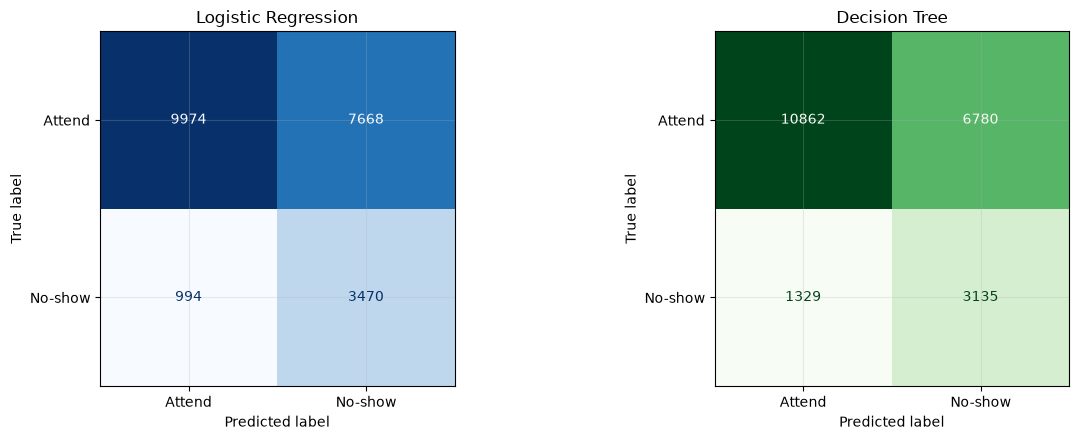

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_pred,
    display_labels=["Attend", "No-show"],
    ax=axes[0],
    cmap="Blues",
    colorbar=False,
)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    tree_pred,
    display_labels=["Attend", "No-show"],
    ax=axes[1],
    cmap="Greens",
    colorbar=False,
)
axes[1].set_title("Decision Tree")

plt.tight_layout()
plt.show()
        

## 8. Compare the two models

In [13]:
comparison = pd.DataFrame([logistic_metrics, tree_metrics]).drop(columns="confusion_matrix")
comparison
        

,model,threshold,roc_auc,accuracy,precision,recall,f1,brier
0,Logistic Regression (calibrated),0.223,0.7205,0.6082,0.3115,0.7773,0.4448,0.1453
1,Decision Tree (calibrated),0.245,0.7221,0.6332,0.3162,0.7023,0.4361,0.1450


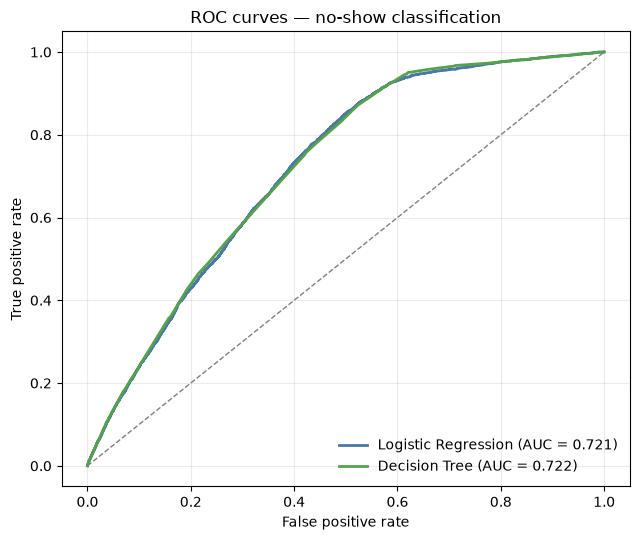

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name, probabilities, color in [
    ("Logistic Regression", logistic_prob, "#4c78a8"),
    ("Decision Tree", tree_prob, "#54a24b"),
]:
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    ax.plot(
        fpr,
        tpr,
        color=color,
        linewidth=2,
        label=f"{name} (AUC = {roc_auc_score(y_test, probabilities):.3f})",
    )
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", linewidth=1)
ax.set_title("ROC curves — no-show classification")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()
        

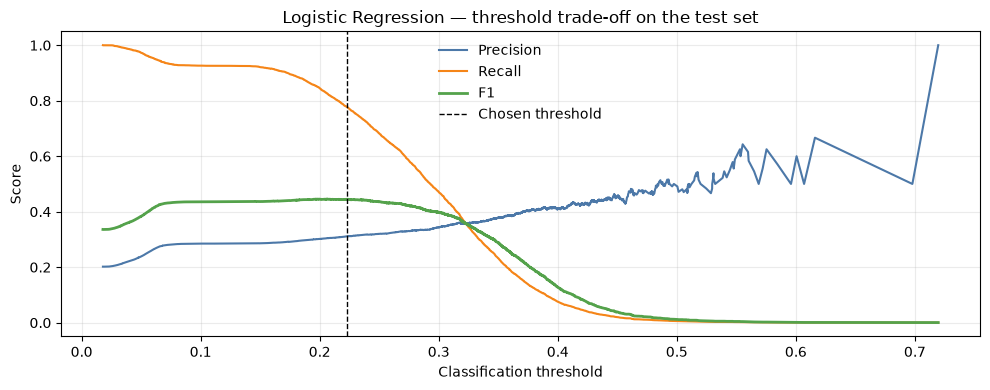

In [15]:
precision, recall, thresholds = precision_recall_curve(y_test, logistic_prob)
f1_scores = 2 * precision * recall / (precision + recall + 1e-9)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(thresholds, precision[:-1], label="Precision", color="#4c78a8")
ax.plot(thresholds, recall[:-1], label="Recall", color="#f58518")
ax.plot(thresholds, f1_scores[:-1], label="F1", color="#54a24b", linewidth=2)
ax.axvline(logistic_threshold, linestyle="--", color="black", linewidth=1, label="Chosen threshold")
ax.set_xlabel("Classification threshold")
ax.set_ylabel("Score")
ax.set_title("Logistic Regression — threshold trade-off on the test set")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
        

## 9. Interpret the decision tree

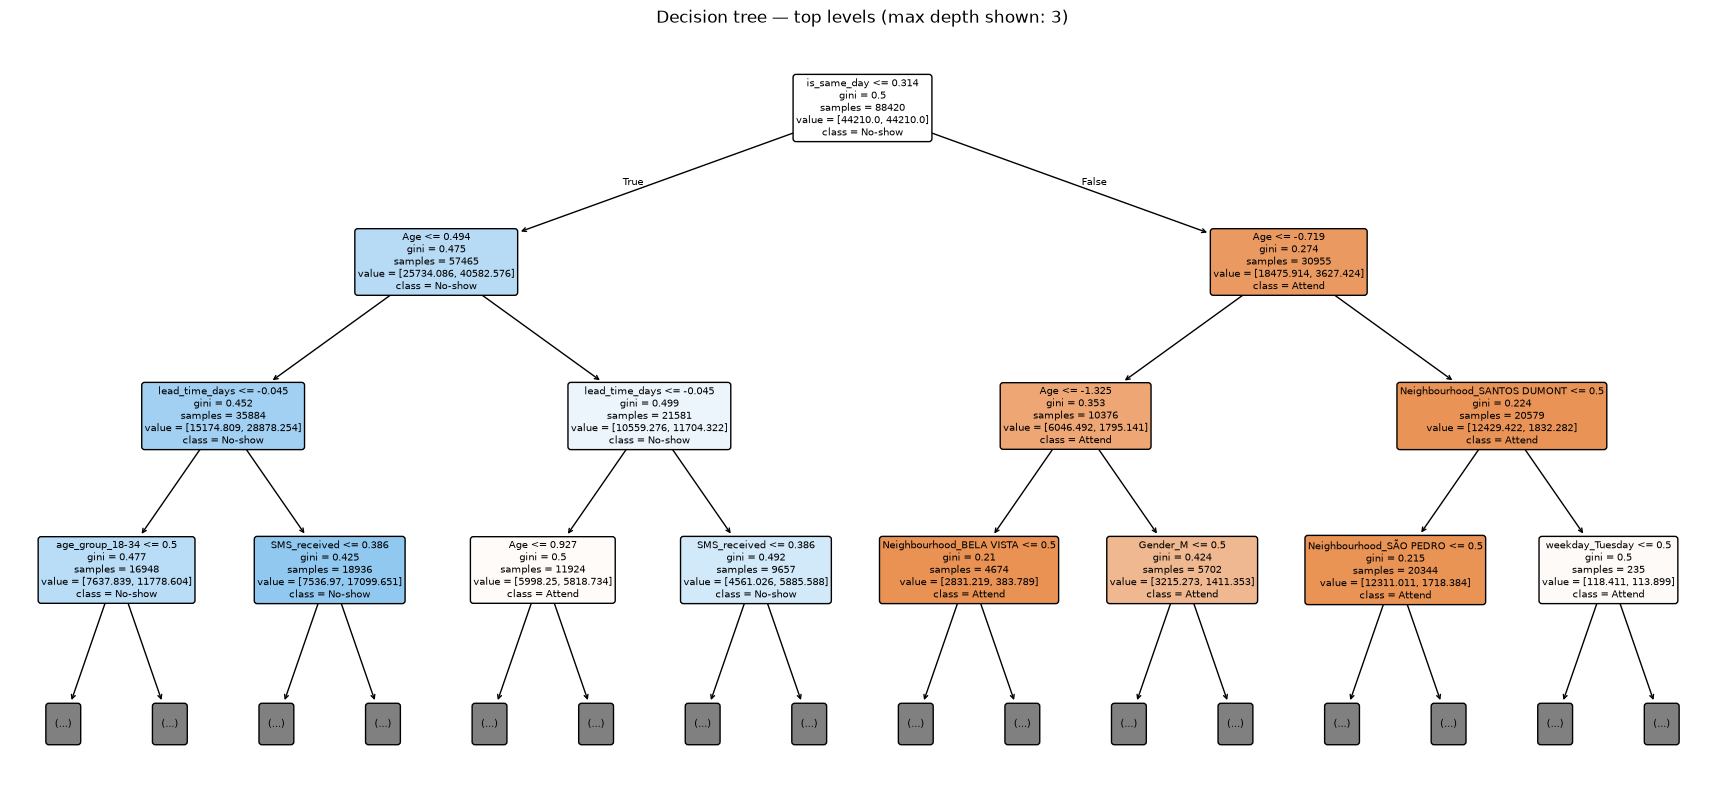

In [16]:
interpretable_tree_pipeline = tree_model.calibrated_classifiers_[0].estimator
tree_classifier = interpretable_tree_pipeline.named_steps["classifier"]
tree_preprocessor = interpretable_tree_pipeline.named_steps["preprocessor"]
tree_feature_names = [
    name.replace("numeric__", "").replace("categorical__", "")
    for name in tree_preprocessor.get_feature_names_out()
]

plt.figure(figsize=(22, 10))
plot_tree(
    tree_classifier,
    max_depth=3,
    feature_names=tree_feature_names,
    class_names=["Attend", "No-show"],
    filled=True,
    rounded=True,
    fontsize=7,
)
plt.title("Decision tree — top levels (max depth shown: 3)")
plt.show()
        

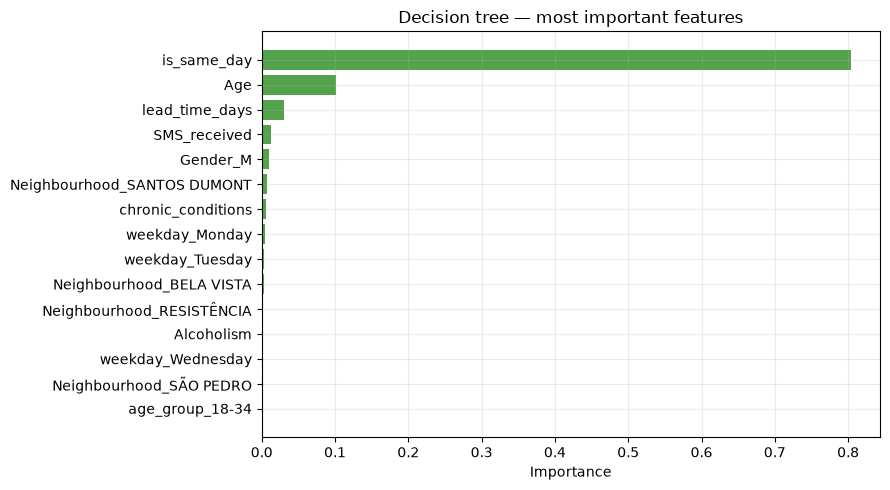

In [17]:
importance = pd.DataFrame(
    {"feature": tree_feature_names, "importance": tree_classifier.feature_importances_}
)
importance = importance[importance["importance"] > 0].sort_values("importance", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(importance["feature"][::-1], importance["importance"][::-1], color="#54a24b")
ax.set_title("Decision tree — most important features")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()
        

In [18]:
interpretable_logistic_pipeline = logistic_model.calibrated_classifiers_[0].estimator
logistic_preprocessor = interpretable_logistic_pipeline.named_steps["preprocessor"]
logistic_feature_names = [
    name.replace("numeric__", "").replace("categorical__", "")
    for name in logistic_preprocessor.get_feature_names_out()
]
logistic_coefficients = pd.DataFrame(
    {
        "feature": logistic_feature_names,
        "coefficient": interpretable_logistic_pipeline.named_steps["classifier"].coef_[0],
    }
)
logistic_coefficients["absolute_coefficient"] = logistic_coefficients["coefficient"].abs()
top_logistic = logistic_coefficients.sort_values("absolute_coefficient", ascending=False).head(15)
top_logistic.sort_values("coefficient").round(3)
        

,feature,coefficient,absolute_coefficient
9,is_same_day,-1.000,1.000
99,age_group_65+,-0.903,0.903
98,age_group_50-64,-0.726,0.726
88,Neighbourhood_SOLON BORGES,-0.435,0.435
31,Neighbourhood_DE LOURDES,-0.408,0.408
97,age_group_35-49,-0.360,0.360
32,Neighbourhood_DO CABRAL,-0.315,0.315
26,Neighbourhood_COMDUSA,-0.258,0.258
60,Neighbourhood_MATA DA PRAIA,-0.248,0.248
44,Neighbourhood_ILHA DAS CAIEIRAS,0.255,0.255


## 10. Save the models and metadata

In [19]:
joblib.dump(logistic_model, MODEL_DIR / "no_show_logistic.joblib")
joblib.dump(tree_model, MODEL_DIR / "no_show_tree.joblib")

risk_low_max = round(logistic_threshold * 0.75, 3)
risk_high_min = round(logistic_threshold * 1.50, 3)

weekday_rates = df.groupby("weekday")["target"].mean().reindex(weekday_order).dropna()
age_rates = df.groupby("age_group", observed=True)["target"].mean().reindex(age_order)
sms_rates = df.groupby("SMS_received")["target"].mean()
lead_rates = df.groupby("lead_bin", observed=True)["target"].mean().reindex(lead_order)

feature_importance_top = [
    {"feature": row.feature, "importance": round(float(row.importance), 4)}
    for row in importance.itertuples()
]
logistic_top = [
    {"feature": row.feature, "coefficient": round(float(row.coefficient), 4)}
    for row in top_logistic.itertuples()
]

no_show_meta = {
    "target": "appointment no-show",
    "models": ["LogisticRegression", "DecisionTreeClassifier"],
    "calibration": "sigmoid (Platt), 3-fold, ensemble=False",
    "trained_at": pd.Timestamp.now().isoformat(timespec="seconds"),
    "n_records": int(len(df)),
    "positive_rate": float(y.mean()),
    "date_range": {
        "start": str(df["AppointmentDay"].min().date()),
        "end": str(df["AppointmentDay"].max().date()),
    },
    "features": {
        "numeric": numeric_features,
        "categorical": categorical_features,
    },
    "thresholds": {
        "logistic": round(logistic_threshold, 4),
        "tree": round(tree_threshold, 4),
    },
    "risk_bands": {
        "low_max": risk_low_max,
        "high_min": risk_high_min,
    },
    "metrics": {
        "logistic": logistic_metrics,
        "tree": tree_metrics,
    },
    "options": {
        "neighbourhoods": sorted(df["Neighbourhood"].unique().tolist()),
        "weekdays": weekday_order,
        "genders": ["F", "M"],
        "age_groups": age_order,
    },
    "eda": {
        "no_show_rate_by_weekday": {str(k): round(float(v), 4) for k, v in weekday_rates.items()},
        "no_show_rate_by_age_group": {str(k): round(float(v), 4) for k, v in age_rates.items()},
        "no_show_rate_by_sms": {str(k): round(float(v), 4) for k, v in sms_rates.items()},
        "no_show_rate_by_lead_bin": {str(k): round(float(v), 4) for k, v in lead_rates.items()},
        "top_neighbourhoods": [
            {
                "neighbourhood": str(idx),
                "no_show_rate": round(float(row["no_show_rate"]), 4),
                "appointments": int(row["appointments"]),
            }
            for idx, row in neighbourhood_stats.head(12).iterrows()
        ],
    },
    "feature_importance_top": feature_importance_top,
    "logistic_coefficients_top": logistic_top,
}

with open(MODEL_DIR / "no_show_meta.json", "w", encoding="utf-8") as f:
    json.dump(no_show_meta, f, indent=2)

print("Saved:")
print(" -", MODEL_DIR / "no_show_logistic.joblib")
print(" -", MODEL_DIR / "no_show_tree.joblib")
print(" -", MODEL_DIR / "no_show_meta.json")
        

Saved:
 - C:\Users\Lenovo\health_analytics\models\no_show_logistic.joblib
 - C:\Users\Lenovo\health_analytics\models\no_show_tree.joblib
 - C:\Users\Lenovo\health_analytics\models\no_show_meta.json


### Result

- Both models use the same features and calibrated probabilities for a fair comparison.
- The logistic model is the primary risk scorer; the decision tree provides a readable classification and feature importance.
- The classification threshold is selected on a validation split and stored in metadata, so the API and dashboard use exactly the same decision rule.
- **Artifacts:** `models/no_show_logistic.joblib`, `models/no_show_tree.joblib`, `models/no_show_meta.json`.
        